<a href="https://colab.research.google.com/github/reinardushansel01-cyber/pemrogJavascript/blob/main/tugas1penguin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

pd.set_option("display.max_columns", None)

df = sns.load_dataset("penguins")
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [2]:
print(df.shape) # (344, 7)
df.info()
df.dtypes

(344, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


,0
species,object
island,object
bill_length_mm,float64
bill_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,object


Pertanyaan

a) Berapa jumlah baris dan kolom?

Terdapat 344 Baris dan 7 Kolom.

b) Sebutkan kolom bertipe numerik, teks, kategori, dan boolean.

Numerik: bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g

Teks / Kategori: species, island, sex

Boolean: Tidak ada kolom bertipe boolean secara eksplisit pada dataset ini.

c) Kolom apa saja yang menurut Anda tidak lengkap, dan dari mana Anda mengetahuinya?

Kolom yang tidak lengkap: bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g, dan sex.

Mengetahuinya dari df.info() yang menunjukkan jumlah non-null count pada kolom-kolom tersebut kurang dari total 344 baris (terdapat nilai missing/NaN).

In [3]:

df.describe()

df.select_dtypes(exclude="number").describe()

print(df["species"].value_counts())
print(df["island"].value_counts())
print(df["sex"].value_counts())

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64
sex
Male      168
Female    165
Name: count, dtype: int64


Pertanyaan

a) Mengapa nilai body_mass_g atau nilai ekstrem perlu dicatat?

Nilai ekstrem atau pencilan (outlier) pada berat badan (body_mass_g) atau panjang paruh perlu dicatat kerana ia mengindikasikan adanya variasi spesies yang signifikan (contohnya penguin Gentoo jauh lebih berat berbanding Adelie dan Chinstrap) atau pencilan data yang boleh mempengaruhi rata-rata (mean).

b) Apakah rata-rata body_mass_g bermakna jika digabungkan tanpa memisahkan spesies?

Mengira rata-rata body_mass_g secara keseluruhan kurang bermakna kerana dataset terdiri daripada spesies berbeza yang mempunyai taburan saiz badan yang berlainan secara biologi. Analisis yang lebih tepat adalah mengelompokkan data berdasarkan species atau sex.

In [6]:

kamus = pd.DataFrame({
    "variabel": df.columns,
    "tipe_pandas": df.dtypes.astype(str).values,
    "n_unik": df.nunique().values,
    "n_missing": df.isna().sum().values,
})

tipe_statistik = {
    "species": "Nominal",
    "island": "Nominal",
    "bill_length_mm": "Rasio (kontinu)",
    "bill_depth_mm": "Rasio (kontinu)",
    "flipper_length_mm": "Rasio (kontinu)",
    "body_mass_g": "Rasio (kontinu)",
    "sex": "Nominal"
}

deskripsi = {
    "species": "Spesies penguin (Adelie, Chinstrap, Gentoo)",
    "island": "Nama pulau tempat penguin ditemukan (Biscoe, Dream, Torgersen)",
    "bill_length_mm": "Panjang paruh penguin dalam milimeter",
    "bill_depth_mm": "Kedalaman/ketebalan paruh penguin dalam milimeter",
    "flipper_length_mm": "Panjang sirip (flipper) penguin dalam milimeter",
    "body_mass_g": "Berat/massa tubuh penguin dalam gram",
    "sex": "Jenis kelamin penguin (Male / Female)"
}

kamus["tipe_statistik"] = kamus["variabel"].map(tipe_statistik)
kamus["deskripsi"] = kamus["variabel"].map(deskripsi)

display(kamus)

kamus.to_csv("kamus_data_penguins.csv", index=False)

,variabel,tipe_pandas,n_unik,n_missing,tipe_statistik,deskripsi
0,species,object,3,0,Nominal,"Spesies penguin (Adelie, Chinstrap, Gentoo)"
1,island,object,3,0,Nominal,"Nama pulau tempat penguin ditemukan (Biscoe, D..."
2,bill_length_mm,float64,164,2,Rasio (kontinu),Panjang paruh penguin dalam milimeter
3,bill_depth_mm,float64,80,2,Rasio (kontinu),Kedalaman/ketebalan paruh penguin dalam milimeter
4,flipper_length_mm,float64,55,2,Rasio (kontinu),Panjang sirip (flipper) penguin dalam milimeter
5,body_mass_g,float64,94,2,Rasio (kontinu),Berat/massa tubuh penguin dalam gram
6,sex,object,2,11,Nominal,Jenis kelamin penguin (Male / Female)


In [7]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=kamus)

MessageError: Error: credential propagation was unsuccessful

In [5]:
# Cek missing value
missing = df.isna().sum().to_frame("jumlah_missing")
missing["persen"] = (missing["jumlah_missing"] / len(df) * 100).round(1)
display(missing.sort_values("persen", ascending=False))

# Cek duplikasi
print("Jumlah duplikat:", df.duplicated().sum())

,jumlah_missing,persen
sex,11,3.2
bill_depth_mm,2,0.6
bill_length_mm,2,0.6
flipper_length_mm,2,0.6
body_mass_g,2,0.6
island,0,0.0
species,0,0.0


Jumlah duplikat: 0


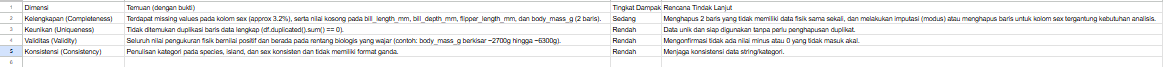